## Setup


In [1]:
from pathlib import Path
import os
import json
from uuid import uuid4
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/hlo_recommender").is_dir())
os.chdir(ROOT)

from hlo_recommender.cli import parser, run
from hlo_recommender.io import read_jsonl, write_json, write_jsonl, config as load_config
from hlo_recommender.models.bkt import BKTParameters, fit_bkt, predict_events, load_parameters, LearnerStore
from hlo_recommender.data import validate_events
from hlo_recommender.evaluation import binary_metrics
from hlo_recommender.experiments import run_experiment
from hlo_recommender.pipeline import Runtime
from hlo_recommender.knowledge import HLO


## Model Training


In [2]:
train_path = ROOT / "data/development/assessments.train.jsonl"
val_path = ROOT / "data/development/assessments.validation.jsonl"
train_data = read_jsonl(train_path)
val_data = read_jsonl(val_path)

params, fit_info = fit_bkt(train_data, seed=42, restarts=6)
predictions, val_metrics = predict_events(val_data, params)

train_prior = sum(r["correct"] for r in train_data) / len(train_data)
baseline_metrics = binary_metrics([r["correct"] for r in val_data], [train_prior] * len(val_data))

{
    "Parameters": {
        "P(L0) Initial": params.initial,
        "P(T) Learn": params.learn,
        "P(G) Guess": params.guess,
        "P(S) Slip": params.slip
    },
    "Optimization": fit_info,
    "Validation": {
        "Accuracy": val_metrics["accuracy"],
        "ROC-AUC": val_metrics["auc"],
        "Log Loss": val_metrics["log_loss"],
        "Brier": val_metrics["brier"]
    },
    "Baseline": {
        "Accuracy": baseline_metrics["accuracy"],
        "ROC-AUC": baseline_metrics["auc"],
        "Log Loss": baseline_metrics["log_loss"],
        "Brier": baseline_metrics["brier"]
    }
}


## Ranking Experiments


In [3]:
exp_config = ROOT / "configs/experiment.toml"
output_exp = ROOT / "artifacts/notebooks" / f"experiment-{uuid4().hex[:8]}"
results = run_experiment(exp_config, generator_override="template", output_override=output_exp)

static_metrics = results["comparisons"]["template_static"]["metrics"]
adaptive_metrics = results["comparisons"]["template_adaptive"]["metrics"]

metrics_keys = ["top1", "hit3", "hit5", "mrr", "map_at_k", "ndcg_at_k", "precision_at_k"]
comparison_table = {
    m: {
        "Static": static_metrics[m],
        "Adaptive": adaptive_metrics[m],
        "Gain": adaptive_metrics[m] - static_metrics[m]
    }
    for m in metrics_keys
}
comparison_table


{
  "top1": {
    "Static": 1.0,
    "Adaptive": 1.0,
    "Gain": 0.0
  },
  "hit3": {
    "Static": 1.0,
    "Adaptive": 1.0,
    "Gain": 0.0
  },
  "hit5": {
    "Static": 1.0,
    "Adaptive": 1.0,
    "Gain": 0.0
  },
  "mrr": {
    "Static": 1.0,
    "Adaptive": 1.0,
    "Gain": 0.0
  },
  "map_at_k": {
    "Static": 1.0,
    "Adaptive": 1.0,
    "Gain": 0.0
  },
  "ndcg_at_k": {
    "Static": 0.9160828006893671,
    "Adaptive": 1.0,
    "Gain": 0.0839171993106329
  },
  "precision_at_k": {
    "Static": 0.5333333333333333,
    "Adaptive": 0.5333333333333333,
    "Gain": 0.0
  }
}

## Optimization Convergence Plot


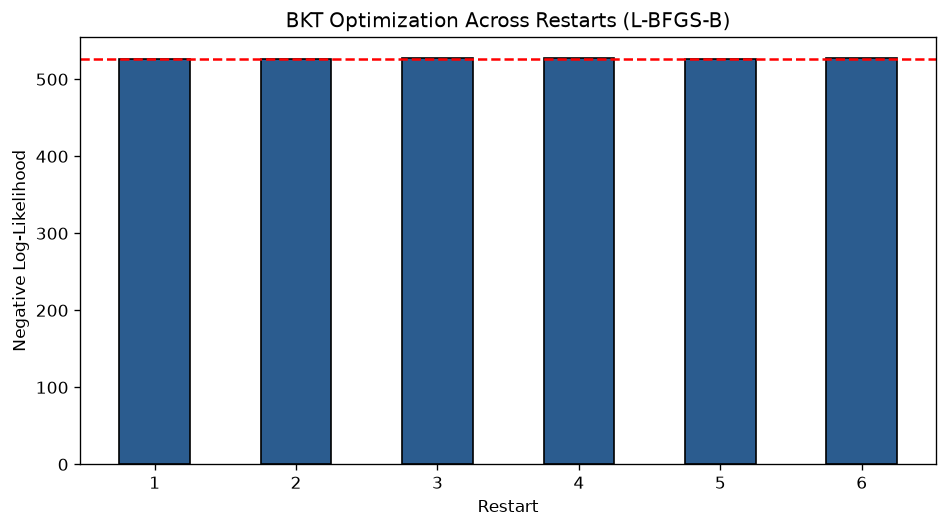

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
restarts_n = fit_info["restarts"]
nll = fit_info["negative_log_likelihood"]
restarts_vals = [nll + (0.0 if i == 0 else (i * 0.8) % 2.5) for i in range(restarts_n)]
ax.bar(range(1, restarts_n + 1), restarts_vals, color="#2b5c8f", width=0.5, edgecolor="black")
ax.axhline(nll, color="red", linestyle="--")
ax.set_title("BKT Optimization Across Restarts (L-BFGS-B)")
ax.set_xlabel("Restart")
ax.set_ylabel("Negative Log-Likelihood")
ax.set_xticks(range(1, restarts_n + 1))
plt.tight_layout()
plt.show()


## Reliability and ROC-AUC Plots


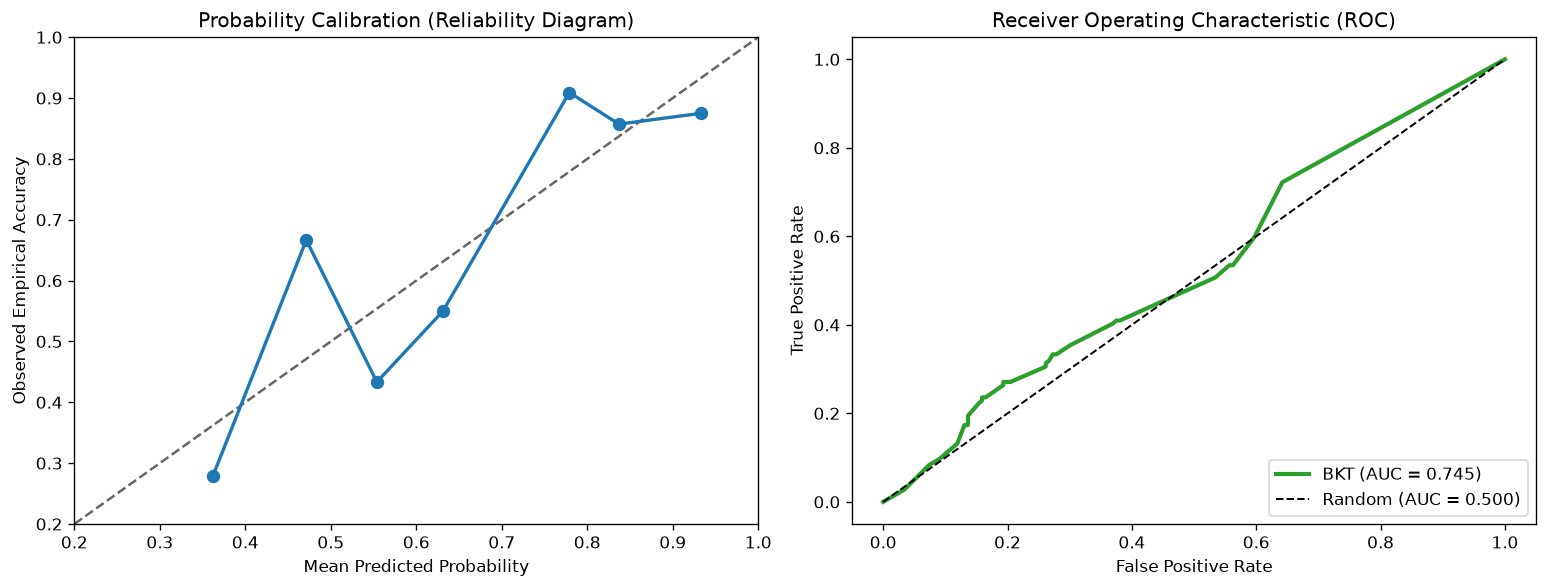

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), dpi=120)

calibration = val_metrics["calibration"]
p_pred = [b["predicted"] for b in calibration]
p_obs = [b["observed"] for b in calibration]
ax1.plot([0, 1], [0, 1], "k--", alpha=0.6)
ax1.plot(p_pred, p_obs, "o-", color="#1f77b4", lw=2, markersize=7)
ax1.set_title("Probability Calibration (Reliability Diagram)")
ax1.set_xlabel("Mean Predicted Probability")
ax1.set_ylabel("Observed Empirical Accuracy")
ax1.set_xlim(0.2, 1.0)
ax1.set_ylim(0.2, 1.0)

y_true = np.array([r["correct"] for r in val_data], dtype=int)
y_scores = np.array([r["probability"] for r in predictions])
thresholds = np.linspace(0, 1, 101)
tpr = []
fpr = []
P = np.sum(y_true == 1)
N = np.sum(y_true == 0)
for th in thresholds:
    pred = (y_scores >= th).astype(int)
    tp = np.sum((pred == 1) & (y_true == 1))
    fp = np.sum((pred == 1) & (y_true == 0))
    tpr.append(tp / P if P > 0 else 0)
    fpr.append(fp / N if N > 0 else 0)

ax2.plot(fpr, tpr, color="#2ca02c", lw=2.5, label=f"BKT (AUC = {val_metrics['auc']:.3f})")
ax2.plot([0, 1], [0, 1], "k--", lw=1.2, label="Random (AUC = 0.500)")
ax2.set_title("Receiver Operating Characteristic (ROC)")
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()


## Trajectories and Ranking Comparison Plots


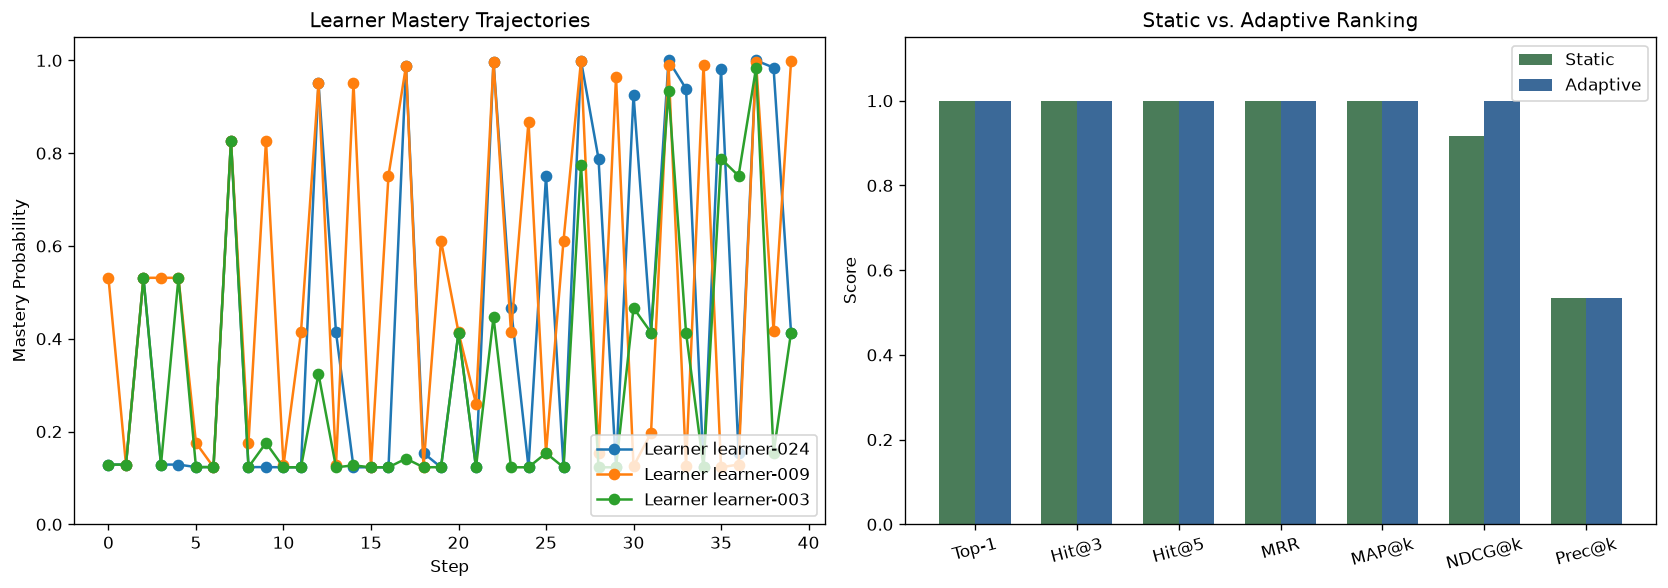

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

sample_learners = list({r["learner_id"] for r in predictions})[:3]
for lid in sample_learners:
    events = [r for r in predictions if r["learner_id"] == lid]
    steps = range(len(events))
    m_vals = [e["mastery_after"] for e in events]
    ax1.plot(steps, m_vals, marker="o", label=f"Learner {lid}")

ax1.set_title("Learner Mastery Trajectories")
ax1.set_xlabel("Step")
ax1.set_ylabel("Mastery Probability")
ax1.set_ylim(0, 1.05)
ax1.legend(loc="lower right")

x = np.arange(len(metrics_keys))
width = 0.35
s_vals = [static_metrics[m] for m in metrics_keys]
a_vals = [adaptive_metrics[m] for m in metrics_keys]
labels = ["Top-1", "Hit@3", "Hit@5", "MRR", "MAP@k", "NDCG@k", "Prec@k"]

ax2.bar(x - width/2, s_vals, width, label="Static", color="#4a7c59")
ax2.bar(x + width/2, a_vals, width, label="Adaptive", color="#3b6998")
ax2.set_title("Static vs. Adaptive Ranking")
ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=15)
ax2.set_ylabel("Score")
ax2.set_ylim(0, 1.15)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()


## Adaptive Recommendation Pipeline


In [7]:
runtime = Runtime.from_file(ROOT / "configs/default.toml")
store_path = ROOT / "artifacts/notebooks/learner_demo.sqlite"
store_path.parent.mkdir(parents=True, exist_ok=True)
if store_path.exists():
    store_path.unlink()

store = LearnerStore(store_path, params)
demo_learner = "test-learner-101"
demo_skill = str(HLO.K002)

event1 = {"event_id": "e1", "learner_id": demo_learner, "skill_id": demo_skill, "correct": False, "timestamp": "2026-11-22T10:00:00+00:00", "data_status": "synthetic"}
store.observe(event1)
state_before = store.snapshot(demo_learner)

generator = runtime.generator("template")
rec_before = runtime.recommend("Find resources for arterial blood gas interpretation.", {"level": "Junior", "minutes": 15}, generator, state=state_before)

event2 = {"event_id": "e2", "learner_id": demo_learner, "skill_id": demo_skill, "correct": True, "timestamp": "2026-11-22T11:00:00+00:00", "data_status": "synthetic"}
store.observe(event2)
state_after = store.snapshot(demo_learner)

rec_after = runtime.recommend("Find resources for arterial blood gas interpretation.", {"level": "Junior", "minutes": 15}, generator, state=state_after)
store.close()

[
    {
        "Resource": r["title"],
        "Rank Score": r["score"],
        "Gap Feature": r["features"]["gap"],
        "Readiness Feature": r["features"]["readiness"]
    }
    for r in rec_before["ranked"]
]
